#  Hospital Operations Statistical Investigation
**AnalystLab Africa – Charity Nduati**

**Primary research question:** *How do recorded total claim costs vary across encounter classes, and are those differences associated with encounter duration and payer coverage?*

**Why it matters:** Finance and operations teams budget by service line (encounter class). If cost behaviour differs strongly by class, or if a large share of encounters has no recorded payer coverage, then class-level budgeting, pricing and payer-negotiation decisions need different assumptions per class.

**Variables required:** `ENCOUNTERCLASS`, `TOTAL_CLAIM_COST`, `BASE_ENCOUNTER_COST`, `PAYER_COVERAGE`, `START`/`STOP` (→ duration), `PAYER` (→ insured flag), `PATIENT` (clustering; age), plus per-encounter procedure counts/costs from `procedures.csv`.

**Privacy:** patient name/address/coordinate columns are *never loaded* (`usecols`); no identifiers are printed or plotted.

**Reproduce:** put the CSVs in `./data` (or set env var `HOSPITAL_DATA_DIR`), then run all cells. Seeds are fixed.

In [1]:
import os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.default_rng(SEED)
def find_data_dir():
    """Look for the CSVs in: $HOSPITAL_DATA_DIR, ./data, ., ../data, .. (first folder containing encounters.csv)."""
    cands = [os.environ.get("HOSPITAL_DATA_DIR"), "data", ".", "../data", ".."]
    for c in filter(None, cands):
        if (Path(c)/"encounters.csv").exists(): return Path(c)
    raise FileNotFoundError("encounters.csv not found. Copy the dataset CSVs into a folder named 'data' next to this notebook "
                            f"(current working directory: {Path.cwd()}) or set HOSPITAL_DATA_DIR to their folder.")
DATA_DIR = find_data_dir(); print("Using data folder:", DATA_DIR.resolve())
FIG_DIR = Path(os.environ.get("FIG_DIR", "figures")); FIG_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
ORDER = ["wellness", "ambulatory", "outpatient", "urgentcare", "emergency", "inpatient"]
PAL = dict(zip(ORDER, sns.color_palette("deep", 6)))
RESULTS = {}   # headline numbers, saved at the end for the report
print("pandas", pd.__version__, "| numpy", np.__version__, "| scipy", stats.__name__)

Using data folder: C:\Users\HomePC\Documents\ShopSmart retail analytics data science project\Hospital-Operations-Statistical-Investigation
pandas 2.0.3 | numpy 1.24.3 | scipy scipy.stats


## 1. Load data (PII columns excluded at load time)

In [2]:
enc = pd.read_csv(DATA_DIR/"encounters.csv", encoding="utf-8-sig")
proc = pd.read_csv(DATA_DIR/"procedures.csv", encoding="utf-8-sig")
payers = pd.read_csv(DATA_DIR/"payers.csv", encoding="utf-8-sig")
orgs = pd.read_csv(DATA_DIR/"organizations.csv", encoding="utf-8-sig", usecols=["Id", "NAME", "CITY", "STATE"])
pat = pd.read_csv(DATA_DIR/"patients.csv", encoding="utf-8-sig", usecols=["Id", "BIRTHDATE", "DEATHDATE", "GENDER", "RACE"])
for n, d in [("encounters", enc), ("procedures", proc), ("payers", payers), ("organizations", orgs), ("patients (non-PII cols only)", pat)]:
    print(f"{n:32s} rows={len(d):>6,}  cols={d.shape[1]}")

encounters                       rows=27,891  cols=14
procedures                       rows=47,701  cols=9
payers                           rows=    10  cols=7
organizations                    rows=     1  cols=4
patients (non-PII cols only)     rows=   974  cols=5


## 2. Data-quality assessment
### 2.1 Does the data dictionary match the files?
The brief warns not to assume every dictionary field exists in every CSV.

In [3]:
dd = pd.read_csv(DATA_DIR/"data_dictionary.csv", encoding="utf-8-sig")
dd = dd[dd["Field"].notna()]
actual_cols = {t: [c.lower() for c in pd.read_csv(DATA_DIR/f"{t}.csv", encoding="utf-8-sig", nrows=0).columns]
               for t in ["encounters", "patients", "payers", "organizations", "procedures"]}
rows = []
for t, g in dd.groupby("Table"):
    documented = [f.lower() for f in g["Field"]]
    rows.append({"table": t,
                 "in_dictionary_not_in_csv": [f for f in documented if f not in actual_cols[t]],
                 "in_csv_not_in_dictionary": [c for c in actual_cols[t] if c not in documented]})
dict_check = pd.DataFrame(rows); print(dict_check.to_string(index=False))
RESULTS["dictionary_mismatch"] = rows

        table   in_dictionary_not_in_csv in_csv_not_in_dictionary
   encounters                         []                       []
organizations                         []                       []
     patients [middle, fips county code]                       []
       payers                         []                       []
   procedures                         []                       []


### 2.2 Missing values, duplicates, keys and referential integrity

In [4]:
def profile(name, d, key=None):
    miss = d.isna().sum(); miss = miss[miss > 0]
    return {"file": name, "rows": len(d), "cols": d.shape[1], "fully_duplicated_rows": int(d.duplicated().sum()),
            "duplicate_keys": int(d[key].duplicated().sum()) if key else "n/a (no key)",
            "columns_with_missing": {k: f"{v:,} ({v/len(d):.1%})" for k, v in miss.items()}}
prof = [profile("encounters", enc, "Id"), profile("procedures", proc), profile("payers", payers, "Id"),
        profile("organizations", orgs, "Id"), profile("patients", pat, "Id")]
for p_ in prof: print(p_)
RESULTS["profiles"] = prof

integrity = {
    "encounters.PATIENT not in patients": int((~enc.PATIENT.isin(pat.Id)).sum()),
    "encounters.PAYER not in payers": int((~enc.PAYER.isin(payers.Id)).sum()),
    "encounters.ORGANIZATION not in organizations": int((~enc.ORGANIZATION.isin(orgs.Id)).sum()),
    "procedures.ENCOUNTER not in encounters": int((~proc.ENCOUNTER.isin(enc.Id)).sum()),
    "procedures.PATIENT != parent encounter's PATIENT": int((proc.merge(enc[["Id", "PATIENT"]], left_on="ENCOUNTER", right_on="Id", suffixes=("", "_e")).eval("PATIENT != PATIENT_e")).sum()),
    "distinct organizations in encounters": int(enc.ORGANIZATION.nunique()),
}
print(); [print(f"{k:55s}{v}") for k, v in integrity.items()]
RESULTS["integrity"] = integrity

{'file': 'encounters', 'rows': 27891, 'cols': 14, 'fully_duplicated_rows': 0, 'duplicate_keys': 0, 'columns_with_missing': {'REASONCODE': '19,541 (70.1%)', 'REASONDESCRIPTION': '19,541 (70.1%)'}}
{'file': 'procedures', 'rows': 47701, 'cols': 9, 'fully_duplicated_rows': 0, 'duplicate_keys': 'n/a (no key)', 'columns_with_missing': {'REASONCODE': '36,945 (77.5%)', 'REASONDESCRIPTION': '36,945 (77.5%)'}}
{'file': 'payers', 'rows': 10, 'cols': 7, 'fully_duplicated_rows': 0, 'duplicate_keys': 0, 'columns_with_missing': {'ADDRESS': '1 (10.0%)', 'CITY': '1 (10.0%)', 'STATE_HEADQUARTERED': '1 (10.0%)', 'ZIP': '1 (10.0%)', 'PHONE': '1 (10.0%)'}}
{'file': 'organizations', 'rows': 1, 'cols': 4, 'fully_duplicated_rows': 0, 'duplicate_keys': 0, 'columns_with_missing': {}}
{'file': 'patients', 'rows': 974, 'cols': 5, 'fully_duplicated_rows': 0, 'duplicate_keys': 0, 'columns_with_missing': {'DEATHDATE': '820 (84.2%)'}}

encounters.PATIENT not in patients                     0
encounters.PAYER not in p

### 2.3 Dates and durations
REASONCODE/REASONDESCRIPTION are legitimately blank when no specific condition was targeted (the dictionary says "only if…"), so they are **not** imputed.

In [5]:
enc["start"] = pd.to_datetime(enc.START, utc=True, errors="coerce")
enc["stop"] = pd.to_datetime(enc.STOP, utc=True, errors="coerce")
enc["dur_h"] = (enc.stop - enc.start).dt.total_seconds() / 3600
enc["year"] = enc.start.dt.year
date_q = {"unparseable START": int(enc.start.isna().sum()), "unparseable STOP": int(enc.stop.isna().sum()),
          "STOP before START": int((enc.dur_h < 0).sum()), "first START": str(enc.start.min()), "last START": str(enc.start.max()),
          "encounters in 2022 (partial year)": int((enc.year == 2022).sum()), "encounters in 2011": int((enc.year == 2011).sum())}
[print(f"{k:40s}{v}") for k, v in date_q.items()]
RESULTS["date_checks"] = date_q
q = enc.groupby("ENCOUNTERCLASS").dur_h.describe(percentiles=[.5, .9, .99]).loc[ORDER].round(2)
print("\nDuration (hours) by class:"); print(q.to_string())
RESULTS["duration_by_class"] = q.reset_index().to_dict("records")
print("\nNon-inpatient encounters lasting > 30 days:", int(((enc.dur_h > 720) & (enc.ENCOUNTERCLASS != "inpatient")).sum()),
      "| inpatient > 30 days:", int(((enc.dur_h > 720) & (enc.ENCOUNTERCLASS == "inpatient")).sum()))

unparseable START                       0
unparseable STOP                        0
STOP before START                       0
first START                             2011-01-02 09:26:36+00:00
last START                              2022-02-05 20:27:36+00:00
encounters in 2022 (partial year)       220
encounters in 2011                      1336

Duration (hours) by class:
                  count   mean     std    min    50%    90%     99%       max
ENCOUNTERCLASS                                                               
wellness         1931.0   0.25    0.00   0.25   0.25   0.25    0.25      0.25
ambulatory      12537.0   9.48  570.67   0.25   0.25   3.07    3.90  44930.00
outpatient       6300.0   5.88  207.12   0.25   0.25   0.25    1.04  10704.00
urgentcare       3666.0   0.25    0.00   0.25   0.25   0.25    0.25      0.25
emergency        2322.0   1.54   14.93   1.00   1.00   1.00    1.71    589.00
inpatient        1135.0  36.84  249.15  24.00  24.00  24.00  220.39   8250.00



**Finding:** wellness and urgent-care encounters all last exactly 15 minutes (zero variance – a default value, not a measurement), and some ambulatory/outpatient encounters span months or years (most plausibly long-running care episodes rather than a single visit). Duration is therefore only informative for some classes; this shapes Hypothesis 2.

### 2.4 Cost fields

In [6]:
cost_q = {
    "negative costs (any cost column)": int((enc[["BASE_ENCOUNTER_COST", "TOTAL_CLAIM_COST", "PAYER_COVERAGE"]] < 0).any(axis=1).sum()),
    "TOTAL_CLAIM_COST == 0": int((enc.TOTAL_CLAIM_COST == 0).sum()),
    "TOTAL_CLAIM_COST < BASE_ENCOUNTER_COST": int((enc.TOTAL_CLAIM_COST < enc.BASE_ENCOUNTER_COST).sum()),
    "PAYER_COVERAGE > TOTAL_CLAIM_COST": int((enc.PAYER_COVERAGE > enc.TOTAL_CLAIM_COST).sum()),
    "PAYER_COVERAGE == 0": int((enc.PAYER_COVERAGE == 0).sum()),
}
[print(f"{k:45s}{v:>8,}") for k, v in cost_q.items()]
print("\nZero-total-claim encounters by class:", enc[enc.TOTAL_CLAIM_COST == 0].ENCOUNTERCLASS.value_counts().to_dict())
print(enc[["BASE_ENCOUNTER_COST", "TOTAL_CLAIM_COST", "PAYER_COVERAGE"]].describe().round(2).to_string())
RESULTS["cost_checks"] = cost_q

negative costs (any cost column)                    0
TOTAL_CLAIM_COST == 0                              89
TOTAL_CLAIM_COST < BASE_ENCOUNTER_COST             89
PAYER_COVERAGE > TOTAL_CLAIM_COST                   0
PAYER_COVERAGE == 0                            13,586

Zero-total-claim encounters by class: {'wellness': 51, 'inpatient': 28, 'emergency': 6, 'ambulatory': 4}
       BASE_ENCOUNTER_COST  TOTAL_CLAIM_COST  PAYER_COVERAGE
count             27891.00          27891.00        27891.00
mean                116.18           3639.68         1114.97
std                  28.41           9205.60         4768.62
min                  85.55              0.00            0.00
25%                  85.55            142.58            0.00
50%                 136.80            278.58           28.44
75%                 142.58           1412.53          155.77
max                 146.18         641882.70       247751.42


**Decision:** the 89 zero-cost claims are *kept* (they may be genuine no-charge encounters; removing them would silently change the population). Log transforms use `log1p`/`log10(x+1)`, and a sensitivity check without them is run in §8.

### 2.5 Do `TOTAL_CLAIM_COST` and the procedure line items reconcile?
Dictionary: total = base + *all* line items (medications, immunizations, procedures, …). We only hold procedures, so `total ≥ base + Σ procedure costs` is expected when procedures are the only items.

In [7]:
pa = proc.groupby("ENCOUNTER").BASE_COST.agg(proc_cost_sum="sum", n_proc="count")
enc = enc.merge(pa, left_on="Id", right_index=True, how="left")
enc["n_proc"] = enc.n_proc.fillna(0).astype(int); enc["proc_cost_sum"] = enc.proc_cost_sum.fillna(0)
enc["resid"] = enc.TOTAL_CLAIM_COST - enc.BASE_ENCOUNTER_COST - enc.proc_cost_sum
rec = {"encounters with no procedure rows": int((enc.n_proc == 0).sum()),
       "total == base + procedures (±$1)": int((enc.resid.abs() <= 1).sum()),
       "total > base + procedures (+$1; other line items)": int((enc.resid > 1).sum()),
       "total < base + procedures (-$1; unexplained)": int((enc.resid < -1).sum())}
[print(f"{k:55s}{v:>8,} ({v/len(enc):.1%})") for k, v in rec.items()]
neg = enc[enc.resid < -1]
print("\nUnexplained-shortfall encounters by class:", neg.ENCOUNTERCLASS.value_counts().to_dict())
RESULTS["reconciliation"] = rec

encounters with no procedure rows                        13,221 (47.4%)
total == base + procedures (±$1)                         13,874 (49.7%)
total > base + procedures (+$1; other line items)         8,801 (31.6%)
total < base + procedures (-$1; unexplained)              5,216 (18.7%)

Unexplained-shortfall encounters by class: {'outpatient': 2449, 'wellness': 1586, 'ambulatory': 1064, 'inpatient': 85, 'emergency': 31, 'urgentcare': 1}


**Interpretation:** about half reconcile exactly; some have extra cost from items we do not hold (expected); a minority have procedures costing *more* than the recorded total. That is a genuine inconsistency (e.g. procedures costed but claim capped/zeroed, or procedures attached to a different billing record). We do not "fix" it; it is documented as a limitation and `total_claim_cost` is analysed as recorded.

### 2.6 Repeated records per patient and patient-level checks

In [8]:
epp = enc.groupby("PATIENT").size()
print(epp.describe().round(1).to_string())
print("Top 1% of patients (by encounter count) account for", f"{epp.sort_values(ascending=False).head(int(len(epp)*0.01)).sum()/len(enc):.1%}", "of encounters")
pat["birth"] = pd.to_datetime(pat.BIRTHDATE); pat["death"] = pd.to_datetime(pat.DEATHDATE, errors="coerce")
enc = enc.merge(pat[["Id", "birth", "death", "GENDER"]].rename(columns={"Id": "PATIENT"}), on="PATIENT", how="left")
enc["age"] = (enc.start.dt.tz_localize(None) - enc.birth).dt.days / 365.25
print("Encounters starting after patient's recorded death date:", int((enc.start.dt.tz_localize(None) > enc.death).sum()))
print("Age at encounter range:", round(float(enc.age.min()), 1), "to", round(float(enc.age.max()), 1))
RESULTS["encounters_per_patient"] = epp.describe().round(1).to_dict()
RESULTS["n_patients_with_encounters"] = int(epp.size)

count     974.0
mean       28.6
std        73.0
min         1.0
25%         4.0
50%        14.0
75%        28.0
max      1381.0
Top 1% of patients (by encounter count) account for 19.6% of encounters
Encounters starting after patient's recorded death date: 68
Age at encounter range: 19.9 to 99.3


**Key implication:** encounters are **not independent**: 974 patients generate ~28k encounters, with a few patients contributing hundreds or over a thousand. Every p-value computed on pooled encounters would be too optimistic, so the analysis adds patient-clustered bootstrap intervals, a patient-level sensitivity test, and cluster-robust regression errors.

## 3. Feature preparation (nothing removed; flags only)

In [9]:
pname = payers.set_index("Id").NAME
enc["payer_name"] = enc.PAYER.map(pname)
enc["insured"] = enc.payer_name != "NO_INSURANCE"
enc["zero_cov"] = enc.PAYER_COVERAGE == 0
enc["cov_ratio"] = np.where(enc.TOTAL_CLAIM_COST > 0, enc.PAYER_COVERAGE / enc.TOTAL_CLAIM_COST, np.nan)
enc["log_cost"] = np.log10(enc.TOTAL_CLAIM_COST + 1)
enc["cls"] = pd.Categorical(enc.ENCOUNTERCLASS, ORDER, ordered=True)
dur_informative = enc.ENCOUNTERCLASS.isin(["ambulatory", "outpatient", "emergency", "inpatient"])   # urgentcare/wellness constant at 0.25 h
print("Encounters:", len(enc), "| patients:", enc.PATIENT.nunique(), "| insured share:", f"{enc.insured.mean():.1%}", "| zero-coverage share:", f"{enc.zero_cov.mean():.1%}")

Encounters: 27891 | patients: 974 | insured share: 68.4% | zero-coverage share: 48.7%


## 4. Exploratory data analysis
### 4.1 Volumes over time and class mix  (Figure 1)

cls
wellness       6.9
ambulatory    45.0
outpatient    22.6
urgentcare    13.1
emergency      8.3
inpatient      4.1

Encounters per year: {2011: 1336, 2012: 2106, 2013: 2495, 2014: 3885, 2015: 2469, 2016: 2451, 2017: 2360, 2018: 2292, 2019: 2228, 2020: 2519, 2021: 3530, 2022: 220}


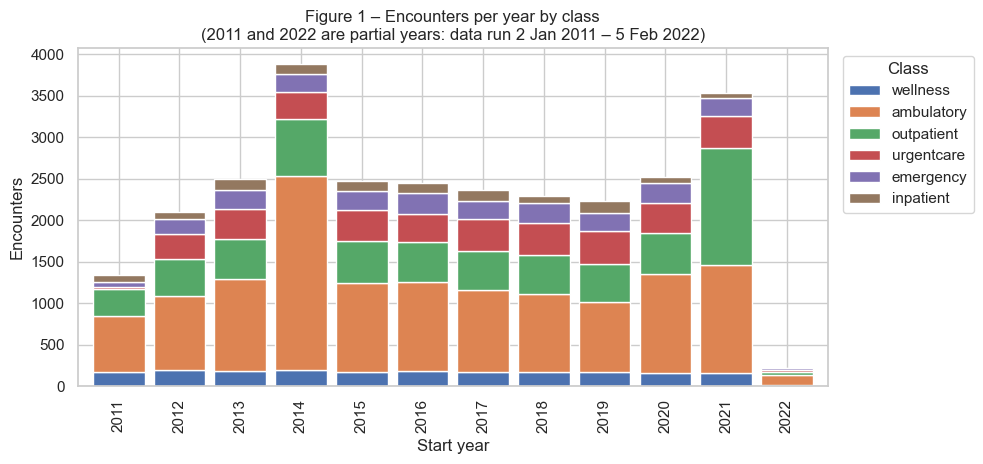

In [10]:
yc = enc.groupby(["year", "cls"]).size().unstack(fill_value=0)[ORDER]
fig, ax = plt.subplots(figsize=(10, 4.8))
yc.plot(kind="bar", stacked=True, ax=ax, color=[PAL[c] for c in ORDER], width=.85)
ax.set_title("Figure 1 – Encounters per year by class\n(2011 and 2022 are partial years: data run 2 Jan 2011 – 5 Feb 2022)")
ax.set_xlabel("Start year"); ax.set_ylabel("Encounters"); ax.legend(title="Class", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.savefig(FIG_DIR/"fig1_encounters_by_year_class.png", dpi=150)
cm = enc.cls.value_counts(normalize=True).loc[ORDER].round(4)
print((cm*100).round(1).to_string()); print("\nEncounters per year:", yc.sum(axis=1).to_dict())
RESULTS["class_mix_pct"] = (cm*100).round(1).to_dict(); RESULTS["encounters_per_year"] = {int(k): int(v) for k, v in yc.sum(axis=1).items()}

### 4.2 Cost distribution by class  (Figures 2 & 3)

                  n    mean  median    p25      p75      p95       max  skew  share_of_total_$
cls                                                                                           
wellness     1931.0  4260.7  1231.4  853.4   1643.7  26823.5   65633.2   2.9               8.1
ambulatory  12537.0  2894.1   574.0  142.6   1267.1  14071.7   65318.9   5.0              35.7
outpatient   6300.0  2237.3   278.6  153.9    594.4  12974.0   43321.6   3.8              13.9
urgentcare   3666.0  6369.2   142.6  142.6   8921.4  32378.4   47998.7   1.6              23.0
emergency    2322.0  4629.7   146.2  146.2   4288.4  25894.5  641882.7  27.5              10.6
inpatient    1135.0  7761.4  2355.6  314.0  14092.3  21184.4  309748.2  11.6               8.7

Top 1% of encounters hold 14.5% of all recorded claim cost; overall mean 3,640 vs median 279


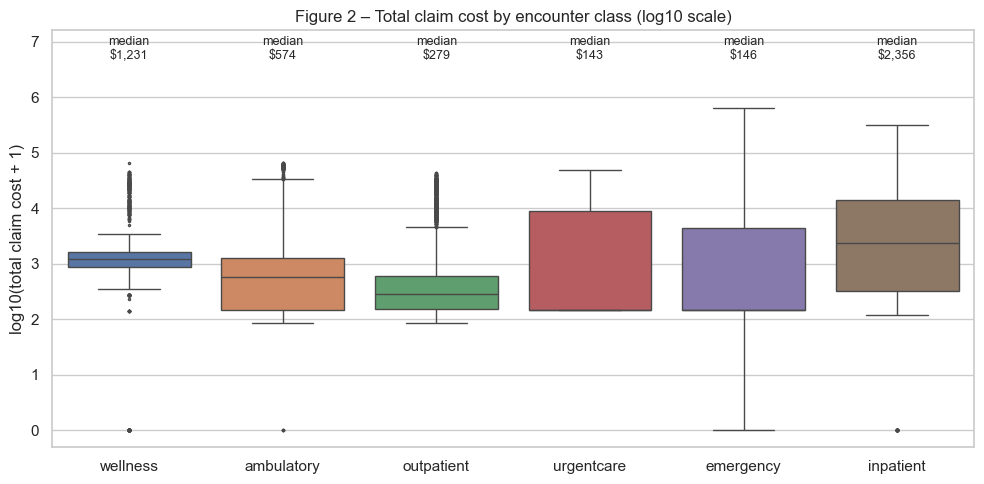

In [11]:
def summ(g):
    c = g.TOTAL_CLAIM_COST
    return pd.Series({"n": len(c), "mean": c.mean(), "median": c.median(), "p25": c.quantile(.25), "p75": c.quantile(.75),
                      "p95": c.quantile(.95), "max": c.max(), "skew": stats.skew(c), "share_of_total_$": c.sum()})
cs = enc.groupby("cls").apply(summ).loc[ORDER]; cs["share_of_total_$"] = (cs["share_of_total_$"]/cs["share_of_total_$"].sum()*100)
print(cs.round(1).to_string())
top1 = enc.TOTAL_CLAIM_COST.sort_values(ascending=False).head(int(len(enc)*.01)).sum() / enc.TOTAL_CLAIM_COST.sum()
print(f"\nTop 1% of encounters hold {top1:.1%} of all recorded claim cost; overall mean {enc.TOTAL_CLAIM_COST.mean():,.0f} vs median {enc.TOTAL_CLAIM_COST.median():,.0f}")
RESULTS["cost_summary_by_class"] = cs.round(2).reset_index().to_dict("records"); RESULTS["top1pct_cost_share"] = round(float(top1), 4)
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=enc, x="cls", y="log_cost", order=ORDER, palette=PAL, fliersize=1.5, ax=ax)
ax.set_title("Figure 2 – Total claim cost by encounter class (log10 scale)"); ax.set_xlabel(""); ax.set_ylabel("log10(total claim cost + 1)")
ax.set_ylim(-0.3, 7.2)
for i, c in enumerate(ORDER): ax.text(i, 7.1, f"median\n${cs.loc[c,'median']:,.0f}", ha="center", va="top", fontsize=9)
plt.tight_layout(); plt.savefig(FIG_DIR/"fig2_cost_boxplot_by_class.png", dpi=150)

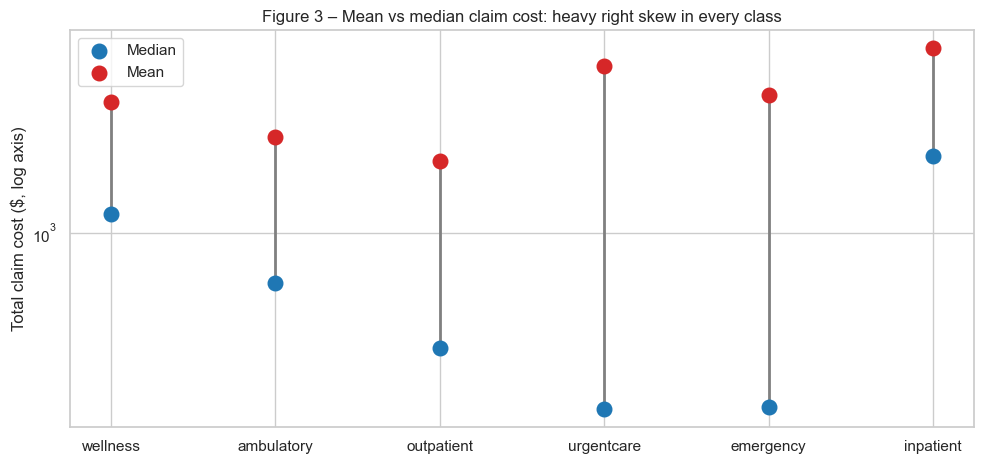

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(6)
ax.vlines(x, cs["median"], cs["mean"], color="grey", lw=2)
ax.scatter(x, cs["median"], s=110, color="#1f77b4", label="Median", zorder=3)
ax.scatter(x, cs["mean"], s=110, color="#d62728", label="Mean", zorder=3)
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels(ORDER); ax.set_ylabel("Total claim cost ($, log axis)")
ax.set_title("Figure 3 – Mean vs median claim cost: heavy right skew in every class"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR/"fig3_mean_vs_median.png", dpi=150)

**What this shows:** means sit far above medians in every class (skew, a few very expensive encounters). Urgent care has a median of ~$143 but a mean above $6k, so *averages mislead* for these data. It cannot show *why* costs differ (case mix, procedures, payer).

### 4.3 Duration (Figure 4) and cost-vs-duration (Figure 5)

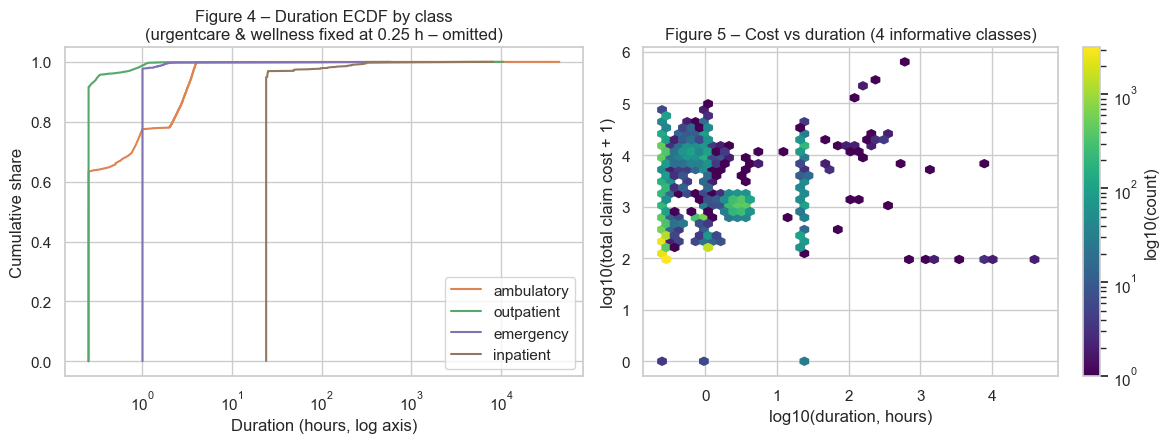

In [13]:
d = enc[dur_informative & (enc.dur_h > 0)]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
for c in ["ambulatory", "outpatient", "emergency", "inpatient"]:
    v = np.sort(d[d.ENCOUNTERCLASS == c].dur_h.values); axs[0].plot(v, np.arange(1, len(v)+1)/len(v), label=c, color=PAL[c])
axs[0].set_xscale("log"); axs[0].set_xlabel("Duration (hours, log axis)"); axs[0].set_ylabel("Cumulative share"); axs[0].legend()
axs[0].set_title("Figure 4 – Duration ECDF by class\n(urgentcare & wellness fixed at 0.25 h – omitted)")
hb = axs[1].hexbin(np.log10(d.dur_h), d.log_cost, gridsize=45, cmap="viridis", mincnt=1, bins="log")
axs[1].set_xlabel("log10(duration, hours)"); axs[1].set_ylabel("log10(total claim cost + 1)"); axs[1].set_title("Figure 5 – Cost vs duration (4 informative classes)")
plt.colorbar(hb, ax=axs[1], label="log10(count)")
plt.tight_layout(); plt.savefig(FIG_DIR/"fig4_5_duration.png", dpi=150)

## 5. Hypothesis 1 – Claim cost differs across encounter classes
* **H0:** the distribution of `TOTAL_CLAIM_COST` is the same in all six classes.  **H1:** at least one class differs (stochastically larger/smaller).
* **Method: Kruskal–Wallis**, then pairwise Mann–Whitney with **Holm** correction.
* **Why not ANOVA?** Cost is extremely right-skewed (skewness in the tens), variances differ massively between classes and group sizes are unequal (checked below). Kruskal–Wallis needs only independent, ordinal-or-better observations with similar *shapes* if read as a median test; otherwise it is read as a test of stochastic dominance, which is how we interpret it.
* **Assumption weak point:** independence – repeated encounters per patient. Addressed by sensitivity analyses below.

In [14]:
groups = [enc.loc[enc.ENCOUNTERCLASS == c, "TOTAL_CLAIM_COST"].values for c in ORDER]
samp = enc.TOTAL_CLAIM_COST.sample(5000, random_state=SEED)
print("Shapiro-Wilk (n=5000 sample) raw  p =", f"{stats.shapiro(samp).pvalue:.2e}", "| on log scale p =", f"{stats.shapiro(np.log10(samp+1)).pvalue:.2e}")
print("Levene (median-centred) on raw cost  p =", f"{stats.levene(*groups, center='median').pvalue:.2e}", "| group sizes:", [len(g) for g in groups])
H, p_kw = stats.kruskal(*groups); N, k = len(enc), 6
eps2 = (H - k + 1) / (N - k)
print(f"\nKruskal–Wallis H = {H:,.1f}, df = 5, p = {p_kw:.3e}; epsilon² (effect size) = {eps2:.3f}")
RESULTS["h1_kw"] = {"H": float(H), "p": float(p_kw), "epsilon2": float(eps2), "N": N}

from itertools import combinations
pw = []
for a, b in combinations(ORDER, 2):
    x_, y_ = enc.loc[enc.ENCOUNTERCLASS == a, "TOTAL_CLAIM_COST"], enc.loc[enc.ENCOUNTERCLASS == b, "TOTAL_CLAIM_COST"]
    U, p_ = stats.mannwhitneyu(x_, y_, alternative="two-sided")
    pw.append({"A": a, "B": b, "P(A>B)+0.5P(tie)": U/(len(x_)*len(y_)), "p_raw": p_})
pw = pd.DataFrame(pw)
o = pw.p_raw.argsort().values; m = len(pw); adj = np.empty(m); run = 0
for r, i in enumerate(o): run = max(run, (m - r) * pw.p_raw.values[i]); adj[i] = min(1, run)
pw["p_holm"] = adj; pw["significant_5%"] = pw.p_holm < .05
print(pw.round(4).to_string(index=False))
RESULTS["h1_pairwise"] = pw.round(5).to_dict("records")

Shapiro-Wilk (n=5000 sample) raw  p = 0.00e+00 | on log scale p = 0.00e+00
Levene (median-centred) on raw cost  p = 2.33e-167 | group sizes: [1931, 12537, 6300, 3666, 2322, 1135]

Kruskal–Wallis H = 2,025.2, df = 5, p = 0.000e+00; epsilon² (effect size) = 0.072
         A          B  P(A>B)+0.5P(tie)  p_raw  p_holm  significant_5%
  wellness ambulatory            0.7173 0.0000  0.0000            True
  wellness outpatient            0.7907 0.0000  0.0000            True
  wellness urgentcare            0.7210 0.0000  0.0000            True
  wellness  emergency            0.7259 0.0000  0.0000            True
  wellness  inpatient            0.4342 0.0000  0.0000            True
ambulatory outpatient            0.5497 0.0000  0.0000            True
ambulatory urgentcare            0.5439 0.0000  0.0000            True
ambulatory  emergency            0.5030 0.6442  0.6442           False
ambulatory  inpatient            0.2645 0.0000  0.0000            True
outpatient urgentcare       

### 5.1 Robustness of H1 to repeated patients
(a) **Patient-clustered bootstrap** 95% CIs for class medians (resample *patients*, not encounters); (b) **patient-level sensitivity**: one value (median cost) per patient per class, then Kruskal–Wallis again.

In [15]:
pids = enc.PATIENT.unique(); pidx = {p: i for i, p in enumerate(pids)}
by = {c: [np.array([]) for _ in pids] for c in ORDER}
for (c, p), g in enc.groupby(["ENCOUNTERCLASS", "PATIENT"]): by[c][pidx[p]] = g.TOTAL_CLAIM_COST.values
B = 1000; med_boot = {c: [] for c in ORDER}
for _ in range(B):
    s = rng.integers(0, len(pids), len(pids))
    for c in ORDER: med_boot[c].append(np.median(np.concatenate([by[c][i] for i in s])))
ci = pd.DataFrame({c: {"median": np.median(np.concatenate(by[c])), "ci_low": np.percentile(med_boot[c], 2.5), "ci_high": np.percentile(med_boot[c], 97.5)} for c in ORDER}).T
print("Cluster-bootstrap median CIs:\n", ci.round(1).to_string())
pl = enc.groupby(["ENCOUNTERCLASS", "PATIENT"]).TOTAL_CLAIM_COST.median().reset_index()
Hp, pp = stats.kruskal(*[pl[pl.ENCOUNTERCLASS == c].TOTAL_CLAIM_COST.values for c in ORDER])
print(f"\nPatient-level Kruskal–Wallis (one median per patient-class; n={len(pl)}): H = {Hp:.1f}, p = {pp:.3e}; patients per class:", pl.ENCOUNTERCLASS.value_counts().loc[ORDER].to_dict())
RESULTS["h1_cluster_ci"] = ci.round(1).reset_index().rename(columns={"index": "class"}).to_dict("records"); RESULTS["h1_patient_level"] = {"H": float(Hp), "p": float(pp), "n": int(len(pl))}

Cluster-bootstrap median CIs:
             median  ci_low  ci_high
wellness    1231.4  1186.9   1285.5
ambulatory   574.0   234.7    787.5
outpatient   278.6   278.6    278.6
urgentcare   142.6   142.6    278.6
emergency    146.2   146.2    160.9
inpatient   2355.6  1186.9  10829.7

Patient-level Kruskal–Wallis (one median per patient-class; n=2393): H = 363.0, p = 2.722e-76; patients per class: {'wellness': 209, 'ambulatory': 695, 'outpatient': 624, 'urgentcare': 247, 'emergency': 465, 'inpatient': 153}


## 6. Hypothesis 2 – Longer encounters have higher claim costs
* **H0:** Spearman ρ between duration and claim cost = 0; **H1:** ρ ≠ 0.
* **Method: Spearman rank correlation** (monotonic association; robust to the extreme durations and costs; Pearson would be dominated by a handful of multi-year episodes).
* **Assumptions:** monotonic relationship, paired observations, reasonable duration measurement. Pooling classes would mix class effects with duration effects (Simpson's paradox risk), so we test **within each class** and omit urgentcare/wellness (duration is constant, ρ undefined). Heavy ties at 0.25 h reduce the effective resolution.
* Intervals: patient-clustered bootstrap (300 reps).

In [16]:
def clustered_rho(df, reps=300):
    r0 = stats.spearmanr(df.dur_h, df.TOTAL_CLAIM_COST)
    g = {p: x[["dur_h", "TOTAL_CLAIM_COST"]].values for p, x in df.groupby("PATIENT")}; keys = list(g); bs = []
    for _ in range(reps):
        arr = np.concatenate([g[keys[i]] for i in rng.integers(0, len(keys), len(keys))])
        bs.append(stats.spearmanr(arr[:, 0], arr[:, 1])[0])
    return r0[0], r0[1], np.percentile(bs, 2.5), np.percentile(bs, 97.5), len(df)
rows = []
for name, sub in [("pooled (4 informative classes)", enc[dur_informative]),] + [(c, enc[enc.ENCOUNTERCLASS == c]) for c in ["ambulatory", "outpatient", "emergency", "inpatient"]]:
    sub = sub[sub.dur_h > 0]; r, p_, lo, hi, n_ = clustered_rho(sub)
    rows.append({"subset": name, "n": n_, "rho": r, "p_value": p_, "ci95_low": lo, "ci95_high": hi, "n_distinct_durations": sub.dur_h.nunique()})
h2 = pd.DataFrame(rows); print(h2.round(4).to_string(index=False))
d99 = enc[dur_informative & (enc.dur_h > 0) & (enc.dur_h <= enc[dur_informative].dur_h.quantile(.99))]
print("\nSensitivity – pooled ρ after trimming durations above the 99th percentile:", round(float(stats.spearmanr(d99.dur_h, d99.TOTAL_CLAIM_COST)[0]), 4), f"(n={len(d99):,})")
RESULTS["h2_spearman"] = h2.round(5).to_dict("records")

                        subset     n    rho  p_value  ci95_low  ci95_high  n_distinct_durations
pooled (4 informative classes) 22294 0.4184      0.0    0.3237     0.4829                  1777
                    ambulatory 12537 0.4766      0.0    0.3941     0.5422                  1379
                    outpatient  6300 0.3925      0.0    0.3345     0.4538                   445
                     emergency  2322 0.1659      0.0    0.0733     0.2431                    38
                     inpatient  1135 0.1734      0.0    0.0633     0.2740                    59

Sensitivity – pooled ρ after trimming durations above the 99th percentile: 0.4171 (n=22,219)


## 7. Hypothesis 3 – The share of encounters with zero payer coverage differs by class
* **H0:** zero-coverage status is independent of encounter class; **H1:** it is associated.
* **Method: chi-square test of independence** + Cramér's V (two categorical variables; every expected cell count is far above 5).
* Because the payer mix (especially `NO_INSURANCE`) may drive this, the test is repeated **among insured encounters only**.
* *Caveat:* "zero coverage" ≠ "uninsured"; insured encounters can show $0 coverage (deductibles, non-covered services, or recording conventions we cannot verify).

All encounters      : chi2 = 381.1, df = 5, p = 3.451e-80, Cramér's V = 0.117, min expected count = 553
Insured only         : chi2 = 797.3, df = 5, p = 4.530e-170, Cramér's V = 0.204, min expected count = 201

                 n  zero_cov_%_all  uninsured_%  zero_cov_%_insured_only  median_coverage_ratio_if_cov>0
cls                                                                                                    
wellness     1931           41.07        17.45                    28.61                            0.80
ambulatory  12537           51.87        35.52                    25.36                            0.66
outpatient   6300           52.41        25.89                    35.79                            0.55
urgentcare   3666           45.77        40.89                     8.26                            0.58
emergency    2322           32.69        23.90                    11.54                            0.58
inpatient    1135           48.55        29.25              

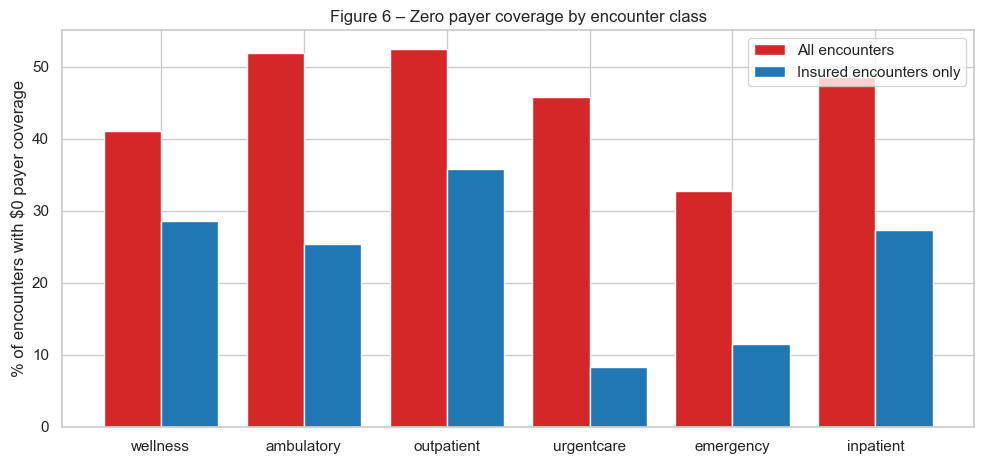

In [17]:
def chi(df, label):
    ct = pd.crosstab(df.ENCOUNTERCLASS, df.zero_cov).loc[ORDER]
    c2, p_, dof, exp = stats.chi2_contingency(ct)
    V = np.sqrt(c2 / (ct.values.sum() * (min(ct.shape) - 1)))
    print(f"{label}: chi2 = {c2:,.1f}, df = {dof}, p = {p_:.3e}, Cramér's V = {V:.3f}, min expected count = {exp.min():.0f}"); return ct, c2, p_, V
ct_all, c2a, pa_, Va = chi(enc, "All encounters      ")
ct_ins, c2i, pi_, Vi = chi(enc[enc.insured], "Insured only         ")
tab = pd.DataFrame({"n": enc.groupby("cls").size(), "zero_cov_%_all": enc.groupby("cls").zero_cov.mean()*100,
                    "uninsured_%": enc.groupby("cls").apply(lambda g: (~g.insured).mean()*100),
                    "zero_cov_%_insured_only": enc[enc.insured].groupby("cls").zero_cov.mean()*100,
                    "median_coverage_ratio_if_cov>0": enc[~enc.zero_cov].groupby("cls").cov_ratio.median()}).loc[ORDER]
print("\n", tab.round(2).to_string())
print("\nOverall zero-coverage encounters:", int(enc.zero_cov.sum()), f"({enc.zero_cov.mean():.1%});  uninsured encounters: {int((~enc.insured).sum())} ({(~enc.insured).mean():.1%});  zero-cov among insured: {enc[enc.insured].zero_cov.mean():.1%}")
RESULTS["h3"] = {"all": {"chi2": float(c2a), "p": float(pa_), "V": float(Va)}, "insured": {"chi2": float(c2i), "p": float(pi_), "V": float(Vi)},
                 "table": tab.round(3).reset_index().to_dict("records"), "overall_zero_cov": int(enc.zero_cov.sum()), "overall_zero_cov_pct": round(float(enc.zero_cov.mean()*100), 1),
                 "uninsured_n": int((~enc.insured).sum()), "zero_cov_insured_pct": round(float(enc[enc.insured].zero_cov.mean()*100), 1)}
fig, ax = plt.subplots(figsize=(10, 4.8)); w = .4; x = np.arange(6)
ax.bar(x - w/2, tab["zero_cov_%_all"], w, label="All encounters", color="#d62728")
ax.bar(x + w/2, tab["zero_cov_%_insured_only"], w, label="Insured encounters only", color="#1f77b4")
ax.set_xticks(x); ax.set_xticklabels(ORDER); ax.set_ylabel("% of encounters with $0 payer coverage"); ax.legend()
ax.set_title("Figure 6 – Zero payer coverage by encounter class"); plt.tight_layout(); plt.savefig(FIG_DIR/"fig6_zero_coverage.png", dpi=150)

## 8. Confounding check – multivariable model (supplementary)
Class differences could simply reflect procedures, duration, age, payer or calendar year. We fit OLS on `ln(1 + TOTAL_CLAIM_COST)` with **patient-clustered robust standard errors** (implemented in NumPy; `statsmodels` not required). Coefficients are read as approximate **% differences relative to ambulatory encounters**, holding the other covariates fixed. This is descriptive: **association, not causation**.

n = 27,891, patients (clusters) = 974, R² = 0.195
                 coef      se        t       p  pct_diff_vs_ambulatory
const          7.8179  0.3209  24.3637  0.0000                     NaN
emergency      0.0772  0.2959   0.2610  0.7941                  8.0300
inpatient     -0.8542  0.5033  -1.6974  0.0899                -57.4389
outpatient    -0.2005  0.1275  -1.5735  0.1159                -18.1713
urgentcare     0.5058  0.3391   1.4915  0.1362                 65.8322
wellness       0.9262  0.1239   7.4737  0.0000                152.4910
ln_duration_h  0.7523  0.1519   4.9534  0.0000                112.1867
n_procedures   0.0987  0.0170   5.8217  0.0000                 10.3711
age_per_10y   -0.1989  0.0254  -7.8420  0.0000                -18.0372
insured       -0.8006  0.2207  -3.6277  0.0003                -55.0932
female        -0.0647  0.1515  -0.4272  0.6693                 -6.2667

Sensitivity excluding 89 zero-cost claims: n=27,802, R²=0.209; class coefficients (ln scale):
 {'

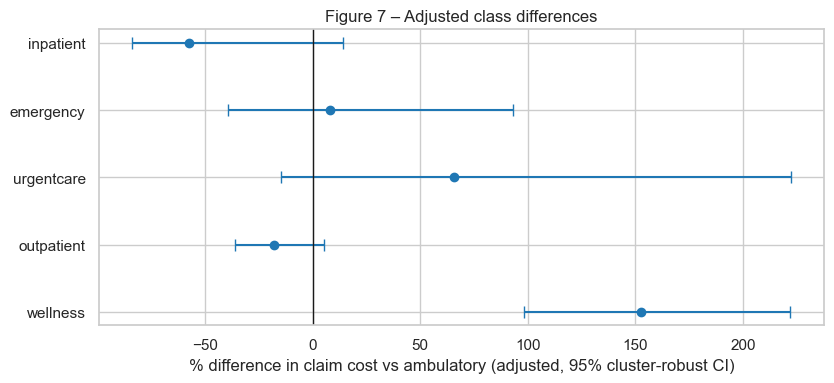

In [18]:
def design(df):
    X = pd.get_dummies(df.ENCOUNTERCLASS, dtype=float).drop(columns="ambulatory")
    X["ln_duration_h"] = np.log1p(df.dur_h.clip(lower=0)); X["n_procedures"] = df.n_proc; X["age_per_10y"] = df.age / 10
    X["insured"] = df.insured.astype(float); X["female"] = (df.GENDER == "F").astype(float)
    X = pd.concat([X, pd.get_dummies(df.year, prefix="yr", dtype=float).drop(columns="yr_2011")], axis=1)
    X.insert(0, "const", 1.0); return X
def ols_cluster(df, ycol="ln_cost"):
    X = design(df); y = df[ycol].values; Xv = X.values; XtXi = np.linalg.inv(Xv.T @ Xv); b = XtXi @ Xv.T @ y; u = y - Xv @ b
    S = pd.DataFrame(Xv * u[:, None]).groupby(df.PATIENT.values).sum().values; G, n, kk = S.shape[0], len(y), Xv.shape[1]
    V = XtXi @ (S.T @ S) @ XtXi * (G/(G-1)) * ((n-1)/(n-kk)); se = np.sqrt(np.diag(V)); t = b/se
    return pd.DataFrame({"coef": b, "se": se, "t": t, "p": 2*stats.t.sf(abs(t), G-1)}, index=X.columns), 1 - (u@u)/((y-y.mean())@(y-y.mean())), n, G
enc["ln_cost"] = np.log1p(enc.TOTAL_CLAIM_COST)
m1, r2, n1, G1 = ols_cluster(enc)
m1["pct_diff_vs_ambulatory"] = (np.exp(m1.coef) - 1) * 100
m1.loc["const", "pct_diff_vs_ambulatory"] = np.nan   # intercept has no % interpretation
show = m1.loc[[i for i in m1.index if not i.startswith("yr_")]]
print(f"n = {n1:,}, patients (clusters) = {G1}, R² = {r2:.3f}"); print(show.round(4).to_string())
m2, r2b, n2, _ = ols_cluster(enc[enc.TOTAL_CLAIM_COST > 0])
print(f"\nSensitivity excluding 89 zero-cost claims: n={n2:,}, R²={r2b:.3f}; class coefficients (ln scale):\n", m2.loc[[c for c in ORDER if c != 'ambulatory']].coef.round(3).to_dict())
RESULTS["ols"] = {"n": n1, "clusters": G1, "r2": float(r2), "coefs": show.round(5).reset_index().rename(columns={"index": "term"}).to_dict("records"), "r2_excl_zero": float(r2b),
                  "class_coefs_excl_zero": m2.loc[[c for c in ORDER if c != 'ambulatory']].coef.round(3).to_dict()}
# Figure 7 – forest plot of class effects
cl = show.loc[[c for c in ORDER if c != "ambulatory"]]; lo = (np.exp(cl.coef - 1.96*cl.se) - 1)*100; hi = (np.exp(cl.coef + 1.96*cl.se) - 1)*100
fig, ax = plt.subplots(figsize=(8.5, 4)); yv = np.arange(len(cl))
ax.errorbar(cl.pct_diff_vs_ambulatory, yv, xerr=[cl.pct_diff_vs_ambulatory - lo, hi - cl.pct_diff_vs_ambulatory], fmt="o", color="#1f77b4", capsize=4)
ax.axvline(0, color="k", lw=1); ax.set_yticks(yv); ax.set_yticklabels(cl.index); ax.set_xlabel("% difference in claim cost vs ambulatory (adjusted, 95% cluster-robust CI)")
ax.set_title("Figure 7 – Adjusted class differences"); plt.tight_layout(); plt.savefig(FIG_DIR/"fig7_adjusted_class_effects.png", dpi=150)

### 8.1 Reconciliation view (Figure 8): claim total vs. base + procedures

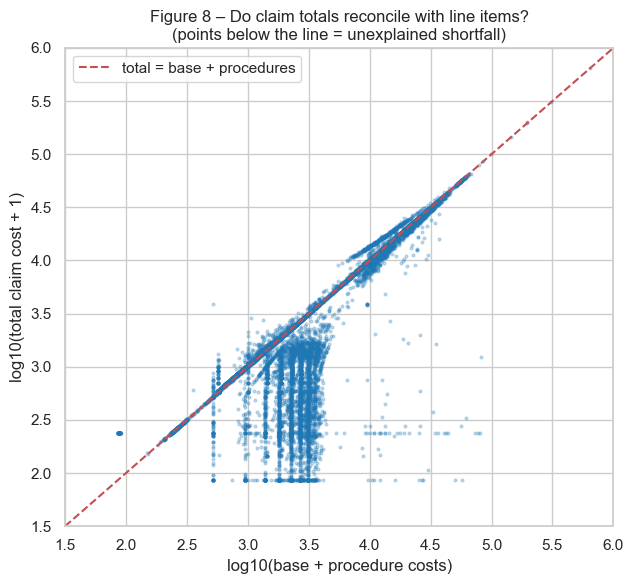

In [19]:
fig, ax = plt.subplots(figsize=(6.5, 6)); s_ = enc[(enc.n_proc > 0)]
ax.scatter(np.log10(s_.BASE_ENCOUNTER_COST + s_.proc_cost_sum), np.log10(s_.TOTAL_CLAIM_COST + 1), s=4, alpha=.25, color="#1f77b4")
lim = [1.5, 6]; ax.plot(lim, lim, "r--", label="total = base + procedures"); ax.set_xlim(lim); ax.set_ylim(1.5, 6)
ax.set_xlabel("log10(base + procedure costs)"); ax.set_ylabel("log10(total claim cost + 1)"); ax.legend()
ax.set_title("Figure 8 – Do claim totals reconcile with line items?\n(points below the line = unexplained shortfall)")
plt.tight_layout(); plt.savefig(FIG_DIR/"fig8_reconciliation.png", dpi=150)

## 9. Validation – independent re-computation of key numbers
Each headline figure is recomputed by a *different route* (SQL on an in-memory SQLite copy; a hand-coded rank formula) and asserted equal.

In [20]:
import sqlite3
con = sqlite3.connect(":memory:")
enc[["Id", "ENCOUNTERCLASS", "TOTAL_CLAIM_COST", "PAYER_COVERAGE"]].to_sql("e", con, index=False)
sql_cls = pd.read_sql("SELECT ENCOUNTERCLASS c, COUNT(*) n, AVG(TOTAL_CLAIM_COST) m FROM e GROUP BY 1", con).set_index("c")
chk1 = np.allclose(sql_cls.loc[ORDER, "n"], cs["n"]) and np.allclose(sql_cls.loc[ORDER, "m"], cs["mean"])
sql_zero = pd.read_sql("SELECT COUNT(*) n FROM e WHERE PAYER_COVERAGE = 0", con).n[0]
chk2 = sql_zero == int(enc.zero_cov.sum())
# Check 3: Kruskal-Wallis from first principles (average ranks, no tie correction then with tie correction)
allv = enc.TOTAL_CLAIM_COST.values; rk = stats.rankdata(allv); lab = enc.ENCOUNTERCLASS.values
Hm = 12/(N*(N+1)) * sum(rk[lab == c].sum()**2/(lab == c).sum() for c in ORDER) - 3*(N+1)
_, tc = np.unique(allv, return_counts=True); Hm /= (1 - (tc**3 - tc).sum()/(N**3 - N))
chk3 = np.isclose(Hm, H, rtol=1e-6)
# Check 4: Spearman = Pearson on ranks
sub = enc[dur_informative & (enc.dur_h > 0)]
chk4 = np.isclose(np.corrcoef(stats.rankdata(sub.dur_h), stats.rankdata(sub.TOTAL_CLAIM_COST))[0, 1], h2.rho.iloc[0], atol=1e-9)
# Check 5: row counts add up and class shares sum to 100%
chk5 = (cs["n"].sum() == len(enc)) and np.isclose(cm.sum(), 1, atol=1e-3)
# Check 6: own OLS reproduces numpy lstsq coefficients
Xt = design(enc); chk6 = np.allclose(np.linalg.lstsq(Xt.values, enc.ln_cost.values, rcond=None)[0], m1.coef.values, atol=1e-6)
checks = {"SQL counts & means match pandas": chk1, "SQL zero-coverage count matches": chk2, "Hand-coded Kruskal-Wallis H matches SciPy": chk3,
          "Spearman equals Pearson-on-ranks": chk4, "Class counts/shares reconcile to total": chk5, "OLS matches lstsq": chk6}
for k_, v_ in checks.items(): print(("PASS  " if v_ else "FAIL  ") + k_)
assert all(checks.values()); RESULTS["validation"] = {k_: bool(v_) for k_, v_ in checks.items()}

PASS  SQL counts & means match pandas
PASS  SQL zero-coverage count matches
PASS  Hand-coded Kruskal-Wallis H matches SciPy
PASS  Spearman equals Pearson-on-ranks
PASS  Class counts/shares reconcile to total
PASS  OLS matches lstsq


## 10. Save headline results

In [21]:
RESULTS["n_encounters"] = int(len(enc))
with open("results.json", "w") as f: json.dump(RESULTS, f, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Saved results.json; figures:", sorted(p.name for p in FIG_DIR.glob("*.png")))

Saved results.json; figures: ['fig1_encounters_by_year_class.png', 'fig2_cost_boxplot_by_class.png', 'fig3_mean_vs_median.png', 'fig4_5_duration.png', 'fig6_zero_coverage.png', 'fig7_adjusted_class_effects.png', 'fig8_reconciliation.png']
